In [1]:
from pathlib import Path
import torchaudio
import torch 

What is the mean duration (in seconds) of the Jazz genre stems in train dataset?

In [2]:
def mean_duration_seconds(root_dir: Path):
    durations = []

    for song_dir in root_dir.iterdir():
        if not song_dir.is_dir():
            continue

        for wav_path in song_dir.glob("*.wav"):
            info = torchaudio.info(wav_path)

            # get in sec
            num_samples = info.num_frames
            sample_rate = info.sample_rate

            duration = num_samples / sample_rate
            durations.append(duration)

    return sum(durations) / len(durations)

jazz_path = Path(r"Z:\dlgen-AI-project\data\genres_stems\jazz")
mean_duration_seconds(jazz_path)

30.03297959183702

What are the unique sample rates present in the dataset? Enter your answer as a comma separated list. Example: [40000, 50000, 60000]

In [3]:
def unique_sample_rates(root_dir: Path):
    sr_set = set()

    for genre_dir in root_dir.iterdir():
        if not genre_dir.is_dir():
            continue

        for song_dir in genre_dir.iterdir():
            if not song_dir.is_dir():
                continue

            for wav_path in song_dir.glob("*.wav"):
                info = torchaudio.info(wav_path)
                sr_set.add(info.sample_rate)

    return sorted(sr_set)

dataset_root = Path(r"Z:\dlgen-AI-project\data\genres_stems")
unique_sample_rates(dataset_root)

[44100]

How many corrupted or zero-byte audio files are present in the train dataset?


In [4]:
def count_corrupted_files(root_dir: Path):
    corrupted = 0
    zero_byte = 0

    for genre_dir in root_dir.iterdir():
        if not genre_dir.is_dir():
            continue

        for song_dir in genre_dir.iterdir():
            if not song_dir.is_dir():
                continue

            for wav_path in song_dir.glob("*.wav"):

                # Check zero-byte
                if wav_path.stat().st_size == 0:
                    zero_byte += 1
                    continue

                # Check corrupted
                try:
                    torchaudio.info(wav_path)
                except Exception:
                    corrupted += 1

    return zero_byte, corrupted, zero_byte + corrupted

train_path = Path(r"Z:\dlgen-AI-project\data\genres_stems")
count_corrupted_files(train_path)

(0, 0, 0)

What is the average peak amplitude (in dB) for vocal stems in train dataset? 

In [5]:
def average_vocal_peak_db(root_dir: Path):
    peak_db_values = []

    for genre_dir in root_dir.iterdir():
        if not genre_dir.is_dir():
            continue

        for song_dir in genre_dir.iterdir():
            if not song_dir.is_dir():
                continue

            # find vocal stem
            for wav_path in song_dir.glob("*vocals*.wav"):

                try:
                    waveform, sr = torchaudio.load(wav_path)
                    waveform = waveform.mean(dim=0)

                    peak = torch.max(torch.abs(waveform)).item()

                    peak_db_values.append(peak)

                except Exception:
                    continue

    return sum(peak_db_values) / len(peak_db_values)

train_path = Path(r"Z:\dlgen-AI-project\data\genres_stems")
average_vocal_peak_db(train_path)

0.5086579895019532

What is the mean spectral centroid for 'blues' genre in the train dataset?

what is spectral centroid means 

brightness of sound 

$$centroid = sum(fk * magnitudek) / sum(magnitudek)$$

| Music            | Centroid      |
| ---------------- | ------------- |
| bass heavy       | low centroid  |
| bright / sharp   | high centroid |
| cymbals, hi-hats | very high     |

metal > pop > blues > classical (typically)

In [6]:
TARGET_SR = 22050
EPS = 1e-10

def mean_blues_centroid(blues_path: Path):
    centroids = []

    spectrogram = torchaudio.transforms.Spectrogram(n_fft=2048, hop_length=512)

    for song_dir in blues_path.iterdir():
        if not song_dir.is_dir():
            continue

        for wav_path in song_dir.rglob("*.wav"):
            try:
                waveform, sr = torchaudio.load(wav_path)
                waveform = waveform.mean(dim=0, keepdim=True)

                if sr != TARGET_SR:
                    waveform = torchaudio.functional.resample(waveform, sr, TARGET_SR)
                    sr = TARGET_SR

                spec = spectrogram(waveform)  # (1, freq, time)
                spec = spec.squeeze(0)

                freqs = torch.linspace(0, sr/2, spec.size(0)).unsqueeze(1)

                centroid = (freqs * spec).sum(dim=0) / (spec.sum(dim=0) + EPS)

                centroids.append(centroid.mean().item())

            except Exception:
                continue

    if len(centroids) == 0:
        print("No valid blues files found!")
        return None

    return sum(centroids) / len(centroids)

blues_path = Path(r"Z:\dlgen-AI-project\data\genres_stems\blues")
mean_blues_centroid(blues_path=blues_path)

1439.0498480510712

Which genre in the train dataset has the highest mean spectral centroid?

In [7]:
from pathlib import Path
import torchaudio
import torch

TARGET_SR = 22050
EPS = 1e-10

def genre_centroid(dataset_root: Path):

    spectrogram = torchaudio.transforms.Spectrogram(n_fft=2048, hop_length=512)

    genre_means = {}

    for genre_dir in dataset_root.iterdir():
        if not genre_dir.is_dir():
            continue

        centroids = []

        for wav_path in genre_dir.rglob("*.wav"):  
            try:
                waveform, sr = torchaudio.load(wav_path)
                waveform = waveform.mean(dim=0, keepdim=True)

                if sr != TARGET_SR:
                    waveform = torchaudio.functional.resample(waveform, sr, TARGET_SR)
                    sr = TARGET_SR

                spec = spectrogram(waveform).squeeze(0)

                freqs = torch.linspace(0, sr/2, spec.size(0)).unsqueeze(1)

                centroid = (freqs * spec).sum(dim=0) / (spec.sum(dim=0) + EPS)

                centroids.append(centroid.mean().item())

            except Exception:
                continue

        if len(centroids) > 0:
            genre_means[genre_dir.name] = sum(centroids) / len(centroids)

    return genre_means

train_root = Path(r"Z:\dlgen-AI-project\data\genres_stems")

results = genre_centroid(train_root)
print(results)
print("\nHighest:", max(results, key=results.get))

{'blues': 1439.0498480510712, 'classical': 1073.1778256297112, 'country': 1417.9403761291503, 'disco': 1633.5252930259705, 'hiphop': 1425.5088393306733, 'jazz': 1801.3017320990562, 'metal': 1781.5601895332336, 'pop': 1492.2515223407745, 'reggae': 1578.051280965805, 'rock': 1408.9293500709534}

Highest: jazz


How many stem audio files in the train dataset contain silence in the first 0.5 seconds?  

If loudness < -60 dBFS → considered silence

samples=0.5×sample_rate

How we measure silence (important)

We do NOT use peak amplitude.
We use RMS energy (real loudness).

𝑅𝑀𝑆 = ((1/𝑁)∑(x^2))**0.5


In [8]:
EPS = 1e-10
SILENCE_THRESHOLD_DB = -60

def count_initial_silence(root_dir: Path):
    silent_files = 0
    total_files = 0

    for genre_dir in root_dir.iterdir():
        if not genre_dir.is_dir():
            continue

        for wav_path in genre_dir.rglob("*.wav"):

            try:
                waveform, sr = torchaudio.load(wav_path)
                waveform = waveform.mean(dim=0)

                # first 0.5 seconds
                num_samples = int(0.5 * sr)

                if waveform.numel() < num_samples:
                    continue

                segment = waveform[:num_samples]

                # RMS
                rms = torch.sqrt(torch.mean(segment**2)).item()

                # dBFS
                db = 20 * torch.log10(torch.tensor(rms + EPS)).item()

                total_files += 1

                if db < SILENCE_THRESHOLD_DB:
                    silent_files += 1

            except Exception:
                continue

    return silent_files, total_files

train_root = Path(r"Z:\dlgen-AI-project\data\genres_stems")
count_initial_silence(train_root)

(756, 4000)

z:\dlgen-AI-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\visha\AppData\Local\Temp\ipykernel_14956\3763572721.py:23: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return [float(tempo), spec_cent, zcr, rolloff]
z:\dlgen-AI-project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
z:\dlgen-AI-project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: Und

Validation Macro F1 Score: 0.1523

Detailed Classification Report:
              precision    recall  f1-score   support

       blues       0.43      0.30      0.35        10
   classical       0.00      0.00      0.00        10
     country       0.12      0.20      0.15        10
       disco       0.21      0.70      0.33        10
      hiphop       0.00      0.00      0.00        10
        jazz       0.08      0.10      0.09        10
       metal       0.38      0.30      0.33        10
         pop       0.00      0.00      0.00        10
      reggae       0.20      0.40      0.27        10
        rock       0.00      0.00      0.00        10

    accuracy                           0.20       100
   macro avg       0.14      0.20      0.15       100
weighted avg       0.14      0.20      0.15       100


BLUES
TP: 3
TN: 86
FP: 4
FN: 7

CLASSICAL
TP: 0
TN: 89
FP: 1
FN: 10

COUNTRY
TP: 2
TN: 76
FP: 14
FN: 8

DISCO
TP: 7
TN: 64
FP: 26
FN: 3

HIPHOP
TP: 0
TN: 89
FP: 1
FN: 10

JA

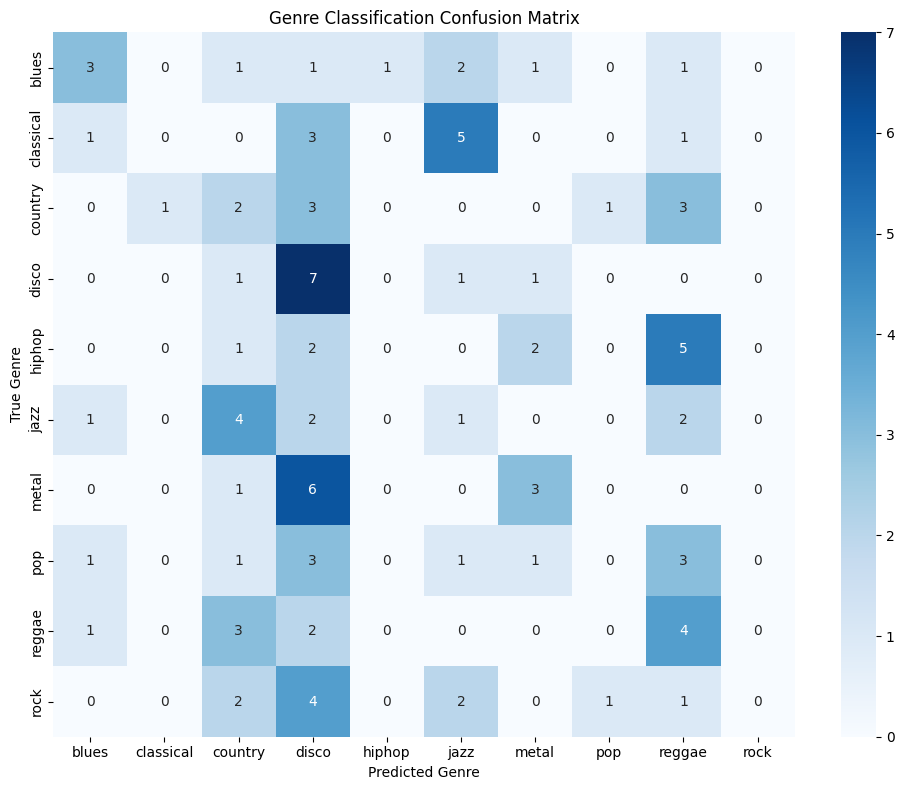

In [9]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, confusion_matrix, classification_report

# --- 1. Setup and Preprocessing ---
ROOT = 'Z:\dlgen-AI-project\data'
STEMS_PATH = os.path.join(ROOT, 'genres_stems')
GENRES = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]

def extract_features(song_path):
    # Load 10s at 22050Hz
    y, sr = librosa.load(os.path.join(song_path, 'other.wav'), sr=22050, duration=10)
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
    spec_cent = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    zcr = np.mean(librosa.feature.zero_crossing_rate(y))
    rolloff = np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
    return [float(tempo), spec_cent, zcr, rolloff]

# --- 2. Data Preparation & Stratified Split ---
data = []
for g in GENRES:
    gp = os.path.join(STEMS_PATH, g)
    songs = [s for s in os.listdir(gp) if os.path.isdir(os.path.join(gp, s))]
    for s in songs[:50]: # Sampling 50 for speed; use all for final
        data.append({'path': os.path.join(gp, s), 'genre': g})

df = pd.DataFrame(data)
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df['genre'], random_state=42)

# --- 3. Model Training (Decision Tree) ---
X_train = np.array([extract_features(p) for p in train_df['path']])
y_train = train_df['genre']
X_val = np.array([extract_features(p) for p in val_df['path']])
y_val = val_df['genre']

clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

'''
YOUR CODE HERE

y_pred = # COMPUTE PREDICTED VALUES
macro_f1 = # COMPUTE VALIDATION MACRO F1 SCORE
cm = # COMPUTE CONFUSION MATRIX
cr = # COMPUTE CLASSIFICATION REPORT

'''

y_pred = clf.predict(X_val)
macro_f1 = f1_score(y_val, y_pred, average="macro")

labels = sorted(GENRES)
cm = confusion_matrix(y_val, y_pred, labels=labels)

cr = classification_report(y_val, y_pred, labels=labels)


print(f"Validation Macro F1 Score: {macro_f1:.4f}\n")
print("Detailed Classification Report:")
print(cr)

'''
YOUR CODE HERE

Visualize the confusion matrix and compute TP, TN, FP, FN for all genres.
'''
metrics = {}
total = np.sum(cm)

for i, genre in enumerate(labels):
    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP
    FP = np.sum(cm[:, i]) - TP
    TN = total - (TP + FP + FN)
    metrics[genre] = {
        "TP": int(TP),
        "TN": int(TN),
        "FP": int(FP),
        "FN": int(FN)
    }
for genre, vals in metrics.items():
    print(f"\n{genre.upper()}")
    print(f"TP: {vals['TP']}")
    print(f"TN: {vals['TN']}")
    print(f"FP: {vals['FP']}")
    print(f"FN: {vals['FN']}")

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=labels, yticklabels=labels)

plt.xlabel("Predicted Genre")
plt.ylabel("True Genre")
plt.title("Genre Classification Confusion Matrix")
plt.tight_layout()
plt.show()